# Regularization

Quay lại bài toán định giá căn hộ của bài 2.1. Lần này bảng dữ liệu rộng hơn hẳn: ngoài diện tích và khoảng cách tới trung tâm còn 30 cột khác, kiểu như số chữ cái trong tên chủ nhà hay ngày trong tuần lúc đăng tin, không cột nào thật sự liên quan tới giá. Trong khi đó chỉ có 40 căn để học. Linear regression khớp 40 căn này gần như hoàn hảo, rồi đoán các căn mới tệ hẳn. Nó không học được quy luật định giá; nó học thuộc 40 căn hộ cụ thể. Bài này chữa bệnh đó bằng regularization: mô hình vẫn phải khớp dữ liệu, nhưng mỗi trọng số lớn đều phải trả giá.

> **Mục tiêu sau bài này**
>
> - Nhận ra mô hình đang học thuộc qua khoảng cách giữa điểm train và test, và giải thích vì sao trọng số lớn là dấu hiệu xấu.
> - Dùng Ridge và Lasso, chọn mức phạt $\lambda$ bằng cross-validation.
> - Giải thích vì sao Lasso đưa được trọng số về đúng 0, còn Ridge thì không.
> - Biết khi nào bắt buộc chuẩn hóa đặc trưng và đọc đúng tham số `alpha`, `C` của scikit-learn.

## Khi mô hình học thuộc

Dữ liệu sinh theo đúng công thức của bài 2.1, chỉ thêm 30 cột ngẫu nhiên không liên quan gì đến giá. 40 căn đầu dùng để học, 60 căn còn lại để kiểm tra. Đặc trưng được chuẩn hóa bằng trung bình và độ lệch chuẩn của tập train, như bài 2.1 đã dặn.

In [ ]:
import numpy as np

rng = np.random.default_rng(1)
n, k = 100, 30
area = rng.uniform(30, 120, n)
dist = rng.uniform(1, 15, n)
junk = rng.normal(size=(n, k))                       # 30 cột không liên quan đến giá
y = 0.05 * area - 0.15 * dist + 1.0 + rng.normal(0, 0.4, n)

X = np.column_stack([area, dist, junk])              # (100, 32)
X_tr, X_te, y_tr, y_te = X[:40], X[40:], y[:40], y[40:]
mu, sigma = X_tr.mean(axis=0), X_tr.std(axis=0)
A_tr, A_te = (X_tr - mu) / sigma, (X_te - mu) / sigma
print(A_tr.shape, A_te.shape)

(40, 32) (60, 32)


Dùng $R^2$ của bài 2.1 để chấm, và giải least squares như cũ:

In [ ]:
def r2(y_hat, y):
    return 1 - np.mean((y_hat - y) ** 2) / np.var(y)

def fit_ols(A, y):
    Ab = np.column_stack([A, np.ones(len(A))])
    theta = np.linalg.lstsq(Ab, y, rcond=None)[0]
    return theta[:-1], theta[-1]

w, b = fit_ols(A_tr, y_tr)
print("R2 train:", round(r2(A_tr @ w + b, y_tr), 3), " R2 test:", round(r2(A_te @ w + b, y_te), 3))
print("2 hệ số thật:", w[:2].round(2), " |hệ số rác| lớn nhất:", np.abs(w[2:]).max().round(2))

R2 train: 0.985  R2 test: 0.349
2 hệ số thật: [ 1.15 -0.79]  |hệ số rác| lớn nhất: 0.44


Điểm train $0.985$, điểm test $0.349$. Khoảng cách lớn như vậy là dấu hiệu kinh điển của overfitting (bài 1.2). Nhìn vào hệ số sẽ thấy vì sao: những cột rác, vốn phải có hệ số 0, lại nhận trọng số tới $0.44$, cỡ một nửa hệ số của khoảng cách. Với 33 tham số và chỉ 40 căn, mô hình luôn tìm được cách dùng các cột rác để khớp nốt phần nhiễu của tập train. Những khớp đó hoàn toàn ngẫu nhiên, nên sang tập test thì chúng gây hại.



**Hỏi nhanh.** Giữ nguyên 40 căn train, nhưng tăng số cột rác từ 30 lên 37. Khi đó có 39 hệ số cộng thêm bias, tức là 40 ẩn cho 40 căn. Không cần chạy code, $R^2$ trên train của least squares sẽ là bao nhiêu?

- A. Vẫn khoảng $0.985$, vì cột rác không mang thông tin về giá
- B. Thấp hơn $0.985$, vì thêm cột rác là thêm nhiễu
- C. Đúng bằng $1$
- D. Chưa đoán được khi chưa biết giá trị các cột rác

<details><summary>Đáp án</summary>

C. Đúng bằng $1$

Có 40 phương trình và 40 ẩn, ma trận lại sinh ngẫu nhiên nên gần như chắc chắn khả nghịch. Hệ có nghiệm khớp đúng từng căn, giống khử Gauss cho một hệ vuông. Least squares cũng không bao giờ làm điểm train tệ đi khi thêm cột, vì luôn có thể cho hệ số của cột mới bằng 0. Điểm train hoàn hảo ở đây chỉ cho biết mô hình đủ chỗ để học thuộc.

</details>

## Phạt độ lớn trọng số

Ý tưởng: thay vì chỉ cực tiểu lỗi, ta cực tiểu lỗi cộng thêm một khoản phạt cho trọng số lớn:

$$J(\mathbf{w}, b) = \underbrace{\sum_{i=1}^{n}\left(\mathbf{w}^\top\mathbf{x}_i + b - y_i\right)^2}_{\text{khớp dữ liệu}} + \underbrace{\lambda\,\Omega(\mathbf{w})}_{\text{phạt độ lớn}}.$$

Vì sao trọng số lớn đáng bị phạt? Khi các đặc trưng cùng thang đo, trọng số lớn nghĩa là dự đoán thay đổi mạnh khi đặc trưng thay đổi một chút. Một mô hình như vậy rất nhạy với những dao động ngẫu nhiên trong dữ liệu, tức variance cao. Khoản phạt buộc mô hình chỉ dùng trọng số lớn khi việc đó giảm lỗi đủ nhiều để bù lại. Điều kiện “cùng thang đo” không phải chi tiết phụ; mục chuẩn hóa ở cuối bài sẽ cho thấy bỏ qua nó thì chuyện gì xảy ra.

Hệ số $\lambda \ge 0$ là núm vặn. $\lambda = 0$ trả về least squares thường. $\lambda$ rất lớn thì mọi trọng số bị ép về 0 và mô hình chỉ còn đoán giá trị trung bình. Ở giữa là điểm cân bằng giữa bias và variance mà ta sẽ tìm bằng validation.

Hai lựa chọn phổ biến nhất cho $\Omega$:

| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Khoản phạt | $\lVert\mathbf{w}\rVert_2^2 = \sum_j w_j^2$ | $\lVert\mathbf{w}\rVert_1 = \sum_j \lvert w_j\rvert$ |
| Tác dụng | Co mọi trọng số về gần 0 | Đưa nhiều trọng số về **đúng** 0 |
| Hợp khi | Nhiều đặc trưng cùng có ích, có tương quan | Chỉ ít đặc trưng thật sự quan trọng |

Bias $b$ không bị phạt. Nó chỉ dời toàn bộ dự đoán lên hoặc xuống cho khớp mức giá trung bình; phạt $b$ sẽ kéo mọi dự đoán về 0 dù dữ liệu nói gì.

**Hỏi nhanh.** Ridge có intercept không bị phạt. Giữ nguyên dữ liệu train và tăng mức phạt $\lambda$ lên rất lớn. Dự đoán sẽ tiến dần về giá trị nào?

- A. Trung vị của `y_train`
- B. Giá trị hay gặp nhất của `y_train`
- C. Trung bình của `y_train`
- D. 0

<details><summary>Đáp án</summary>

C. Trung bình của `y_train`

Các hệ số của feature bị co về 0, chỉ còn lại intercept. Hằng số làm tổng bình phương lỗi nhỏ nhất là trung bình, không phải trung vị hay giá trị hay gặp nhất. Đáp án 0 chỉ đúng nếu intercept cũng bị phạt.

</details>

## Ridge

Với khoản phạt L2, đạo hàm của $\lambda\lVert\mathbf{w}\rVert^2$ là $2\lambda\mathbf{w}$, nên nghiệm đóng chỉ thêm đúng một số hạng so với bài 2.1. Để không phạt $b$, ta trừ trung bình khỏi các cột của $X$ và khỏi $\mathbf{y}$ trước (gọi là $X_c$, $\mathbf{y}_c$), giải $\mathbf{w}$, rồi lấy $b = \bar y - \bar{\mathbf{x}}^\top\mathbf{w}$:

$$\mathbf{w}^\ast_{\text{ridge}} = \left(X_c^\top X_c + \lambda I\right)^{-1} X_c^\top \mathbf{y}_c.$$

Số hạng $\lambda I$ cộng $\lambda$ vào mọi trị riêng của $X_c^\top X_c$, nên ma trận luôn khả nghịch khi $\lambda > 0$. Ridge vì vậy chữa luôn chuyện đa cộng tuyến ở bài 2.1: khi hai đặc trưng gần như trùng nhau, least squares có thể cho $+500$ và $-499$, còn Ridge chia đều thành kiểu $0.5$ và $0.5$.



In [ ]:
def fit_ridge(A, y, lam):
    a_mean, y_mean = A.mean(axis=0), y.mean()
    Ac, yc = A - a_mean, y - y_mean
    w = np.linalg.solve(Ac.T @ Ac + lam * np.eye(A.shape[1]), Ac.T @ yc)
    return w, y_mean - a_mean @ w

from sklearn.linear_model import Ridge
w, b = fit_ridge(A_tr, y_tr, 3.0)
model = Ridge(alpha=3.0).fit(A_tr, y_tr)
print(np.allclose(w, model.coef_), np.allclose(b, model.intercept_))

True True


Hàm mất mát của `Ridge` trong scikit-learn đúng bằng $J$ ở trên, với `alpha` chính là $\lambda$, nên hai kết quả trùng nhau.

**Hỏi nhanh.** Lấy nghiệm Ridge với $\lambda = 3$ làm điểm xuất phát, rồi chạy gradient descent của bài 2.1 trên tổng bình phương lỗi **không** có khoản phạt, với bước nhỏ và chạy đủ lâu. Trọng số sẽ đi về đâu?

- A. Đứng yên, vì nghiệm Ridge đã là điểm tối ưu
- B. Dịch dần về nghiệm least squares
- C. Dao động mãi quanh nghiệm Ridge
- D. Co dần về 0

<details><summary>Đáp án</summary>

B. Dịch dần về nghiệm least squares

Tại nghiệm Ridge, gradient của riêng phần lỗi bằng $-2\lambda\mathbf{w}$, khác 0, nên gradient descent vẫn đi tiếp. Phần lỗi là hàm lồi, và ở đây $X_c^\top X_c$ khả nghịch, nên nó dừng ở cực tiểu duy nhất của phần lỗi, chính là nghiệm least squares. Muốn trọng số đứng yên ở nghiệm Ridge thì phải chạy gradient descent trên $J$ có cả khoản phạt.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q4(a), (d)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=8)

</details>

Giờ thử nhiều mức phạt:

In [ ]:
for lam in [0, 0.1, 1, 3, 10, 30, 100]:
    w, b = fit_ridge(A_tr, y_tr, lam)
    print(f"lambda = {lam:>5}: R2 train = {r2(A_tr @ w + b, y_tr):.3f}   R2 test = {r2(A_te @ w + b, y_te):.3f}")

lambda =     0: R2 train = 0.985   R2 test = 0.349
lambda =   0.1: R2 train = 0.985   R2 test = 0.644
lambda =     1: R2 train = 0.982   R2 test = 0.839
lambda =     3: R2 train = 0.974   R2 test = 0.839
lambda =    10: R2 train = 0.934   R2 test = 0.764
lambda =    30: R2 train = 0.814   R2 test = 0.603
lambda =   100: R2 train = 0.547   R2 test = 0.356


Đây là bias–variance trên một bảng số. Tăng $\lambda$ thì điểm train luôn giảm, vì mô hình bị trói tay. Điểm test thì tăng rồi giảm: lúc đầu khoản phạt dập tắt các hệ số rác (giảm variance), về sau nó dập luôn cả hai hệ số thật (tăng bias). Đỉnh nằm quanh $\lambda$ từ 1 đến 3, nâng $R^2$ test từ $0.349$ lên $0.839$.



**Hỏi nhanh.** Ở dòng $\lambda = 100$ của bảng, $R^2$ trên train là $0.547$, trên test là $0.356$. Mô hình đang gặp vấn đề gì?

- A. Variance cao, vì vẫn còn học thuộc tập train
- B. Bias cao, vì phạt quá mạnh nên khớp không nổi cả tập train
- C. Không có vấn đề gì, vì khoảng cách train và test đã nhỏ hơn ở $\lambda = 0$
- D. Dữ liệu test bị lỗi, vì điểm test thấp hơn ở $\lambda = 3$

<details><summary>Đáp án</summary>

B. Bias cao, vì phạt quá mạnh nên khớp không nổi cả tập train

Khoảng cách giữa train và test nhỏ lại chưa có nghĩa là mô hình tốt, vì chính điểm train đã thấp. Phạt mạnh co cả hai hệ số thật về gần 0, nên mô hình quá đơn giản so với quy luật. Đó là underfitting.

</details>

## Lasso

Ridge co mọi hệ số về phía 0 nhưng gần như không bao giờ đưa hệ số nào về đúng 0. Lasso dùng khoản phạt $\lVert\mathbf{w}\rVert_1$ thì làm được. Mấu chốt nằm ở góc nhọn của $\lvert w\rvert$ tại 0; cũng vì góc nhọn đó mà Lasso không có nghiệm đóng.

Có hai cách nhìn vì sao. Cách thứ nhất là hình học: bài toán có phạt tương đương với cực tiểu lỗi trong một vùng ràng buộc $\Omega(\mathbf{w}) \le t$. Vùng L2 là hình tròn, vùng L1 là hình thoi có góc nằm trên các trục. Các đường đồng mức của lỗi là những elip lan dần ra từ nghiệm least squares, và lần đầu chạm hình thoi thường là ở một góc, nơi có một tọa độ bằng 0.



Cách thứ hai là tính thẳng trong trường hợp đơn giản nhất: các cột của $X$ trực chuẩn ($X^\top X = I$), và $z_j = \mathbf{x}_j^\top \mathbf{y}$ là hệ số least squares. Từ đây đến hết bài, Lasso được viết với hệ số $\tfrac12$ trước phần lỗi, $\tfrac12\sum_i r_i^2 + \lambda\lVert\mathbf{w}\rVert_1$, để công thức gọn; Ridge vẫn dùng $J$ như trên. Khi đó mỗi trọng số được tính riêng:

$$w_j^{\text{ridge}} = \frac{z_j}{1 + \lambda}, \qquad w_j^{\text{lasso}} = \operatorname{sign}(z_j)\,\max\!\left(\lvert z_j\rvert - \lambda,\ 0\right).$$

Ridge co mọi hệ số theo cùng một tỉ lệ. Lasso trừ đi một lượng cố định $\lambda$ rồi cắt về 0; phép biến đổi này gọi là soft-thresholding. Hệ số nào có độ lớn dưới $\lambda$ biến mất hoàn toàn.



**Hỏi nhanh.** Lasso dùng hàm $\frac12\|y-Xw\|^2+\lambda\|w\|_1$, với $X^\top X=I$. Một hệ số least squares bằng $z = 0.8$, và $\lambda = 1$. Hệ số Lasso tương ứng bằng bao nhiêu?

- A. 0
- B. 0.8
- C. 0.4
- D. $-0.2$

<details><summary>Đáp án</summary>

A. 0

Soft-thresholding cho $\operatorname{sign}(z)\max(|z|-\lambda, 0) = 0$. Ra $-0.2$ là lấy $|z| - \lambda$ mà quên cắt về 0; Lasso không bao giờ làm hệ số đổi dấu. Ra 0.4 là dùng quy tắc co theo tỉ lệ của Ridge.

</details>

Khi các cột không trực chuẩn, Lasso được giải bằng coordinate descent: lần lượt tối ưu từng $w_j$ trong khi giữ các trọng số khác cố định. Mỗi bước con chính là một phép soft-thresholding như trên. Với dữ liệu đã trừ trung bình, cài đặt chỉ khoảng mười dòng:

In [ ]:
def soft(z, t):
    return np.sign(z) * np.maximum(np.abs(z) - t, 0)

def fit_lasso(A, y, lam, sweeps=500):
    a_mean, y_mean = A.mean(axis=0), y.mean()
    Ac, yc = A - a_mean, y - y_mean
    w = np.zeros(A.shape[1])
    col_sq = (Ac ** 2).sum(axis=0)
    for _ in range(sweeps):
        for j in range(len(w)):
            r_j = yc - Ac @ w + Ac[:, j] * w[j]       # phần dư khi bỏ đặc trưng j
            w[j] = soft(Ac[:, j] @ r_j, lam) / col_sq[j]
    return w, y_mean - a_mean @ w

w, b = fit_lasso(A_tr, y_tr, 8.0)
print("giữ lại các cột:", np.nonzero(w)[0], " hệ số:", w[w != 0].round(3))
print("R2 test:", round(r2(A_te @ w + b, y_te), 3))

giữ lại các cột: [0 1]  hệ số: [ 1.037 -0.408]
R2 test: 0.891


Với $\lambda = 8$, Lasso giữ lại đúng hai cột đầu là diện tích và khoảng cách, loại cả 30 cột rác. Không ai nói cho nó biết cột nào là rác. Lasso vừa ước lượng vừa chọn đặc trưng (feature selection) trong cùng một bước.

`Lasso` của scikit-learn dùng hàm mất mát $\tfrac{1}{2n}\sum_i r_i^2 + \alpha\lVert\mathbf{w}\rVert_1$, tức chia hàm của ta cho $n$. Nghiệm không đổi nếu `alpha` $= \lambda / n$:

In [ ]:
from sklearn.linear_model import Lasso
model = Lasso(alpha=8.0 / 40, tol=1e-10, max_iter=100000).fit(A_tr, y_tr)
print(np.allclose(w, model.coef_, atol=1e-6), np.allclose(b, model.intercept_, atol=1e-6))

True True


## Ví dụ tính tay

Cho $\mathbf{z} = (3,\ 0.5,\ -1.2)$ và $\lambda = 1$, các cột trực chuẩn.

- Ridge: $\mathbf{w} = (1.5,\ 0.25,\ -0.6)$. Mọi hệ số giảm một nửa, không hệ số nào về 0.
- Lasso: $\mathbf{w} = (2,\ 0,\ -0.2)$. Đặc trưng thứ hai bị loại; hai đặc trưng còn lại mỗi cái mất đúng 1 đơn vị độ lớn.



**Hỏi nhanh.** Vẫn $\mathbf{z} = (3,\ 0.5,\ -1.2)$, các cột trực chuẩn. Với Lasso, $\lambda$ nhỏ nhất bằng bao nhiêu thì **cả ba** hệ số đều bằng 0?

- A. $0.5$
- B. $1.2$
- C. $3$
- D. Không có, vì Lasso luôn giữ ít nhất một feature

<details><summary>Đáp án</summary>

C. $3$

Hệ số thứ $j$ bằng 0 khi $\lambda \ge \lvert z_j\rvert$, nên cần $\lambda \ge \max_j \lvert z_j\rvert = 3$. Từ mức ấy trở lên, mô hình chỉ còn intercept, đúng như giới hạn $\lambda \to \infty$ ở mục trước. Thư viện dùng chính giá trị này làm điểm bắt đầu khi vẽ hệ số theo $\lambda$.

</details>

## Chọn λ bằng cross-validation

Ở mục Ridge, ta đã chọn $\lambda$ bằng cách nhìn thẳng vào $R^2$ test. Làm vậy để quan sát bias–variance thì được, nhưng con số $0.839$ đó không còn là ước lượng khách quan: chính tập test đã được dùng để chọn. $\lambda$ là siêu tham số (hyperparameter). Nó không học được từ tập train, vì trên tập train thì $\lambda = 0$ luôn thắng, nên phải chọn bằng cross-validation (bài 1.3) trên một lưới thang log, ví dụ $10^{-3}, 10^{-2}, \dots, 10^{3}$. Tập test chỉ được dùng một lần, ở cuối.

Bước chuẩn hóa cũng học từ dữ liệu (trung bình và độ lệch chuẩn), nên phải được fit lại bên trong từng fold. Cách gọn nhất là gói `StandardScaler` và mô hình vào một `Pipeline`, rồi để `GridSearchCV` dò `alpha`:

In [ ]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alpha_grid = np.logspace(-3, 3, 13)
for name, estimator in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=10000))]:
    pipeline = make_pipeline(StandardScaler(), estimator)
    step_name = name.lower()
    search = GridSearchCV(pipeline, {step_name + "__alpha": alpha_grid}, cv=5)
    search.fit(X_tr, y_tr)
    alpha = search.best_params_[step_name + "__alpha"]
    coef = search.best_estimator_[-1].coef_
    print(f"{name}: alpha = {alpha:.4g}  R2 test = {search.score(X_te, y_te):.3f}  "
          f"số hệ số khác 0 = {np.count_nonzero(coef)}")
    print(f"       2 hệ số thật = {coef[:2].round(3)}  |hệ số rác| lớn nhất = {np.abs(coef[2:]).max():.3f}")

Ridge: alpha = 3.162  R2 test = 0.837  số hệ số khác 0 = 32
       2 hệ số thật = [ 1.092 -0.504]  |hệ số rác| lớn nhất = 0.170
Lasso: alpha = 0.03162  R2 test = 0.925  số hệ số khác 0 = 14
       2 hệ số thật = [ 1.234 -0.527]  |hệ số rác| lớn nhất = 0.096


Ridge chọn `alpha` $\approx 3.16$, rơi đúng vào vùng $\lambda$ từ 1 đến 3 đã thấy ở bảng trước, nhưng lần này không cần nhìn tập test. Lasso đạt $R^2$ test $0.925$, cao hơn cả mức $0.891$ của Lasso với $\lambda = 8$, dù vẫn giữ 12 cột rác. So hai dòng hệ số là thấy lý do. Với $\lambda = 8$, Lasso loại sạch rác nhưng co luôn hai hệ số thật xuống $1.037$ và $-0.408$. Mức phạt nhỏ hơn do CV chọn giữ hai hệ số thật ở $1.234$ và $-0.527$, còn các cột rác sống sót chỉ có hệ số nhỏ hơn $0.1$ và gây hại không đáng kể. Cross-validation tối ưu điểm dự đoán; nó không cam kết tìm đúng tập đặc trưng thật.

**Hỏi nhanh.** Lasso với $\lambda = 8$ loại sạch 30 cột rác, còn Lasso do cross-validation chọn vẫn giữ 12 cột rác. Vậy mà bản thứ hai lại dự đoán tốt hơn trên test, $0.925$ so với $0.891$. Vì sao?

- A. Vì phạt mạnh cũng co cả hai hệ số thật, gây bias lớn
- B. Vì 12 cột rác ấy thật ra có liên quan đến giá
- C. Vì cross-validation đã nhìn thấy tập test
- D. Vì mô hình có nhiều feature hơn luôn dự đoán tốt hơn

<details><summary>Đáp án</summary>

A. Vì phạt mạnh cũng co cả hai hệ số thật, gây bias lớn

Bias do co hệ số thật gây hại nhiều hơn vài hệ số rác nhỏ. Một $\lambda$ chung phạt mọi hệ số như nhau, nên không thể vừa ép rác về 0 vừa để yên hệ số thật. Các hệ số rác còn lại đều dưới $0.1$, còn hai hệ số thật bị co từ khoảng $1.23$ xuống $1.04$ và từ $-0.53$ xuống $-0.41$. Cross-validation cũng không hề thấy tập test, nó chỉ chia tập train thành các fold.

</details>

Vẽ các hệ số theo $\lambda$ (regularization path) sẽ thấy rõ quá trình chọn lọc: khi phạt tăng, các cột rác rơi về 0 trước, hai cột thật trụ lại lâu nhất.



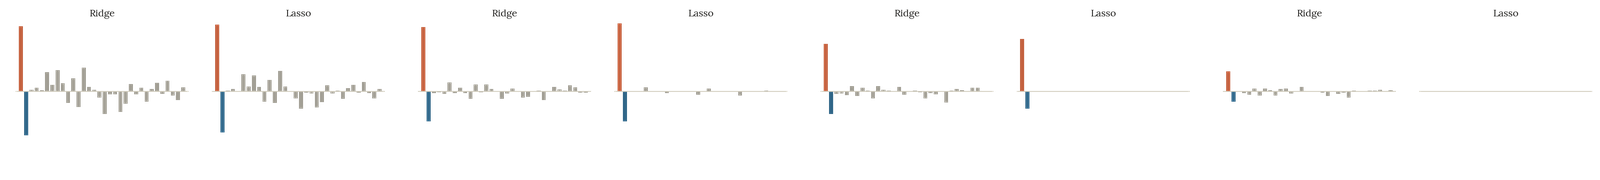

## Chuẩn hóa trước khi phạt

Khoản phạt tính trên độ lớn trọng số, mà độ lớn trọng số phụ thuộc đơn vị đo. Đổi khoảng cách từ km sang m (nhân 1000) thì hệ số của nó nhỏ đi 1000 lần để giữ nguyên dự đoán, và khoản phạt $w^2$ nhỏ đi $10^6$ lần. Cùng một $\lambda$, đặc trưng đó gần như không còn bị phạt. Thử với Ridge trên hai đặc trưng thật, chưa chuẩn hóa:

In [ ]:
B = X_tr[:, :2]                                     # diện tích (m²), khoảng cách (km)
for unit, scale in [("km", 1), ("m", 1000)]:
    M = B * np.array([1, scale])                     # khoảng cách đo bằng km hoặc bằng m
    m = Ridge(alpha=1000).fit(M, y_tr)
    print(f"khoảng cách theo {unit:>2}: hệ số quy về mỗi km = {m.coef_[1] * scale:.3f}")

khoảng cách theo km: hệ số quy về mỗi km = -0.058
khoảng cách theo  m: hệ số quy về mỗi km = -0.175


Cùng dữ liệu, cùng $\lambda$, chỉ đổi đơn vị. Tính theo km thì hệ số khoảng cách bị ép mạnh về phía 0; tính theo m thì nó gần như không bị phạt, cho đúng hệ số của linear regression không phạt trên 40 căn này ($-0.175$). Mức phạt mà mỗi đặc trưng phải chịu phụ thuộc vào đơn vị của nó, không phụ thuộc vào việc nó quan trọng đến đâu. Chuẩn hóa đưa mọi đặc trưng về cùng thang đo để khoản phạt công bằng.



**Hỏi nhanh.** Đổi một feature từ km sang m mà vẫn giữ nguyên dự đoán, thì hệ số của feature ấy giảm 1000 lần. Nếu giữ nguyên $\lambda$, khoản phạt L2 trên riêng hệ số này thay đổi thế nào?

- A. Giảm 1000 lần
- B. Tăng 1 000 000 lần
- C. Không đổi
- D. Giảm 1 000 000 lần

<details><summary>Đáp án</summary>

D. Giảm 1 000 000 lần

L2 phạt bình phương của hệ số: $(w/1000)^2 = w^2/10^6$. Với L1, khoản phạt chỉ giảm 1000 lần, nhưng kết luận vẫn thế: không chuẩn hóa thì mức phạt phụ thuộc vào đơn vị.

</details>

> **Tên gọi trong thư viện**
>
> scikit-learn gọi $\lambda$ là `alpha`, nhưng mỗi lớp nhân thêm hệ số khác nhau: `Ridge` dùng tổng bình phương, `Lasso` và `ElasticNet` dùng $\tfrac{1}{2n}$ lần tổng bình phương. Chép `alpha` từ `Ridge` sang `Lasso` là sai thang đo. Với `LogisticRegression` và `SVC` thì dùng `C`, tỉ lệ nghịch với $\lambda$: `C` nhỏ là phạt mạnh.

## Elastic Net

Khi nhiều đặc trưng tương quan mạnh với nhau, Lasso có xu hướng giữ một cái và bỏ các cái còn lại, khá tùy ý. Elastic Net trộn hai khoản phạt, $\lambda\left(\rho\lVert\mathbf{w}\rVert_1 + \tfrac{1-\rho}{2}\lVert\mathbf{w}\rVert_2^2\right)$ với $\rho \in [0, 1]$, nên vẫn thưa nhưng giữ được cả nhóm đặc trưng tương quan. $\rho = 1$ là Lasso, $\rho = 0$ là Ridge. Trong scikit-learn, $\rho$ là `l1_ratio`.



**Hỏi nhanh.** Có ba cột gần trùng nhau, cùng đo một thứ và cùng có ích, cộng thêm vài cột nhiễu. Elastic Net với `l1_ratio=0.5` thường làm gì với ba cột ấy?

- A. Bỏ cả ba, vì phạt L1 cộng L2 mạnh hơn Lasso
- B. Giữ đúng một cột như Lasso, vì vẫn còn phần L1
- C. Giữ cả ba, với hệ số lớn hơn của least squares
- D. Giữ cả ba, với hệ số chia gần đều cho nhau

<details><summary>Đáp án</summary>

D. Giữ cả ba, với hệ số chia gần đều cho nhau

Phần L2 ưu tiên chia đều, giống Ridge với hai cột trùng nhau, còn phần L1 vẫn đưa các cột nhiễu về 0. Thử với ba cột gần trùng và ba cột nhiễu, Elastic Net cho khoảng $0.97$, $0.99$, $1.00$ ở ba cột trùng và gần 0 ở các cột nhiễu. Phạt chỉ co hệ số lại, không làm chúng lớn hơn least squares.

</details>

## Regularization ở khắp nơi

Ý tưởng “lỗi cộng phạt” xuất hiện trong gần như mọi mô hình của khóa học:

- `C` trong logistic regression (bài 2.3) và SVM (bài 2.8).
- Độ sâu tối đa và số mẫu tối thiểu ở lá của decision tree (bài 2.5).
- Phạt L1, L2 trên giá trị lá trong XGBoost và LightGBM (bài 2.7).
- Weight decay, dropout, early stopping trong mạng neural (bài 3.6).

Ở góc nhìn xác suất, phạt L2 tương đương giả định trọng số có phân phối chuẩn quanh 0, còn phạt L1 tương đương phân phối Laplace, có đỉnh nhọn tại 0. Đó là một cách khác để hiểu vì sao L1 “thích” số 0.

**Hỏi nhanh.** So `LogisticRegression(C=0.01)` với `LogisticRegression(C=100)`. Khác nhau thế nào?

- A. `C=0.01` phạt mạnh hơn, trọng số nhỏ hơn
- B. `C=0.01` phạt yếu hơn, trọng số lớn hơn
- C. Như nhau, vì `C` chỉ ảnh hưởng tốc độ
- D. `C` là số vòng lặp

<details><summary>Đáp án</summary>

A. `C=0.01` phạt mạnh hơn, trọng số nhỏ hơn

`C` tỉ lệ nghịch với $\lambda$. `C` nhỏ ứng với $\lambda$ lớn, tức là phạt mạnh. Ai đã quen `alpha` của `Ridge` rất dễ đọc ngược chiều.

</details>

## Khi đi thi

- **Nhiều đặc trưng thưa** (one-hot hàng nghìn cột, TF-IDF hàng chục nghìn cột): mô hình tuyến tính có phạt L2 là baseline mạnh và rất nhanh.
- **Nghi có nhiều đặc trưng rác**: chạy Lasso để xem cột nào sống sót, rồi dùng thông tin đó cho mô hình khác.
- **Ít mẫu, nhiều đặc trưng**: regularization không còn là tùy chọn mà là bắt buộc.
- **Dò `alpha` hoặc `C` trên thang log**, không dò trên thang đều. Khác biệt giữa 0.1 và 1 thường quan trọng hơn giữa 5 và 6.
- **Chuẩn hóa trong pipeline**: `make_pipeline(StandardScaler(), Ridge())` để cross-validation tự chuẩn hóa đúng trên từng fold.
- **Chọn bằng cross-validation, không bằng bảng điểm công khai**: nộp nhiều lần rồi giữ cấu hình có điểm public cao nhất cũng là chọn $\lambda$ bằng tập test, và điểm cuối thường tụt.

## Tóm tắt

- Regularization cực tiểu lỗi cộng phạt độ lớn trọng số; $\lambda$ điều khiển cân bằng bias–variance. Bias $b$ không bị phạt.
- Ridge (L2) có nghiệm đóng $(X_c^\top X_c + \lambda I)^{-1}X_c^\top\mathbf{y}_c$, co mọi hệ số về phía 0 và giữ nghiệm ổn định khi đặc trưng tương quan.
- Lasso (L1) cắt hệ số nhỏ về đúng 0 bằng soft-thresholding, nên chọn được đặc trưng; cái giá là hệ số thật cũng bị co.
- Chuẩn hóa trước khi phạt; chọn $\lambda$ bằng cross-validation trên lưới log, không bằng tập test; để ý thang đo của `alpha` và chiều ngược của `C`.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** Ridge cho $R^2$ train $0.99$ nhưng $R^2$ validation chỉ $0.35$. Ta nghi mô hình đang overfit. Thí nghiệm nào kiểm điều đó hợp lý nhất?

- A. Giảm $\lambda$ cho $R^2$ train gần 1 hơn
- B. Chọn $\lambda$ bằng cách chấm nhiều lần trên test
- C. Bỏ scaler, giữ $\lambda$, vì khoản phạt không phụ thuộc thang đo
- D. Thử $\lambda$ lớn hơn trên cùng các fold, rồi so lỗi train và validation

<details><summary>Đáp án</summary>

D. Thử $\lambda$ lớn hơn trên cùng các fold, rồi so lỗi train và validation

Nếu đúng là overfit, tăng $\lambda$ sẽ làm điểm train giảm và điểm validation tăng, ít nhất trong một khoảng nào đó. Giảm $\lambda$ là đi ngược hướng. Chấm nhiều lần trên test thì test thành validation. Còn khoản phạt thì có phụ thuộc thang đo.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 2 · Q3.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=12)

</details>

**Câu 2.** Xét Ridge với $J(w)=\frac12\|y-Xw\|^2+\frac\lambda2\|w\|^2$, $X^\top X=I$ và $X^\top y=z$. Một tọa độ của $z$ bằng 4, và $\lambda = 1$. Hệ số tương ứng bằng bao nhiêu?

- A. 3
- B. 0
- C. 2
- D. 4

<details><summary>Đáp án</summary>

C. 2

Điều kiện tối ưu là $(I+\lambda I)w = z$, nên $w_j = 4/(1+1) = 2$. Ra 3 là áp nhầm soft-thresholding của Lasso.

</details>

**Câu 3.** Với Lasso $J(w)=\frac12\|y-Xw\|^2+\lambda\|w\|_1$, $X^\top X=I$, tọa độ $z_j=(X^\top y)_j=-2.5$ và $\lambda=1$. Hệ số tối ưu bằng bao nhiêu?

- A. $-1.5$
- B. $-2.5$
- C. $-1.25$
- D. 0

<details><summary>Đáp án</summary>

A. $-1.5$

Soft-thresholding cho $\operatorname{sign}(z_j)\max(|z_j|-\lambda, 0) = -1.5$: độ lớn giảm đúng $\lambda$, dấu giữ nguyên. Ra $-1.25$ là chia cho $1 + \lambda$, quy tắc của Ridge.

</details>

**Câu 4.** Trên cùng một bộ dữ liệu, ta học hai mô hình hồi quy tuyến tính với cùng mức phạt $\lambda > 0$. Mô hình A phạt L1, mô hình B phạt L2. Điều gì nhiều khả năng xảy ra nhất?

- A. A và B có số trọng số khác 0 bằng nhau.
- B. A có ít trọng số khác 0 hơn B.
- C. B có ít trọng số khác 0 hơn A.
- D. Cả hai đều không thể có trọng số đúng bằng 0.
- E. Không có cách nào biết mô hình nào có ít trọng số khác 0 hơn.

<details><summary>Đáp án</summary>

B. A có ít trọng số khác 0 hơn B.

L1 cắt các hệ số nhỏ về đúng 0, còn L2 chỉ co chúng lại. Phương án cuối là cái bẫy của chữ “nhiều khả năng”: từng trường hợp cụ thể có thể khác, nhưng xu hướng thì rõ.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 1.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=1)

</details>

**Câu 5.** Một bộ dữ liệu y khoa có 50 bệnh nhân, mỗi người đo 100 chỉ số. Một mô hình phân loại tuyến tính đúng 98% trên train, tức 49/50, nhưng chỉ đúng 62% trên validation, và gần như mọi trọng số đều khác 0. Đâu là chẩn đoán đúng nhất?

- A. Underfitting, vì 50 mẫu quá ít để mô hình nào học được
- B. Lệch lớp, nên mô hình chỉ đoán lớp đông hơn
- C. Các chỉ số khác đơn vị nên thuật toán không hội tụ
- D. Overfitting, vì 100 trọng số cho 50 mẫu là đủ chỗ học thuộc

<details><summary>Đáp án</summary>

D. Overfitting, vì 100 trọng số cho 50 mẫu là đủ chỗ học thuộc

Đây là câu hỏi “37 cột rác” ở đầu bài, phiên bản phân loại: số tham số nhiều hơn số mẫu thì điểm train gần như hoàn hảo dù không học được gì. Underfitting, lệch lớp hay không hội tụ đều kéo cả điểm train xuống, trái với 98% ở đây. Cách chữa tự nhiên là phạt L1 hoặc L2 và chọn mức phạt bằng cross-validation. Nếu nghi chỉ vài chỉ số thật sự quan trọng, nên thử L1 trước.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 269](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=96)

</details>

**Câu 6.** Hai feature gần như trùng nhau. Linear regression thường cho hai hệ số kiểu $+500$ và $-499$. Ridge thì thường cho kết quả nào?

- A. Hai hệ số gần bằng nhau
- B. $+1000$ và $-999$
- C. Một hệ số đúng bằng 0
- D. Không giải được vì ma trận suy biến

<details><summary>Đáp án</summary>

A. Hai hệ số gần bằng nhau

Ridge chia đều phần đóng góp, vì với cùng tổng $a + b$, cặp chia đều cho $a^2 + b^2$ nhỏ nhất. Nhờ vậy Ridge ổn định khi các feature tương quan với nhau. Khoản phạt cũng làm $X_c^\top X_c+\lambda I$ khả nghịch, nên lúc nào cũng giải được. Đưa hẳn một hệ số về 0 là kiểu của Lasso.

</details>

**Câu 7.** Một bạn học Ridge, thử $\lambda$ = 0.01, 0.1, 1, 10, so lỗi trên train, validation và test, rồi chọn $\lambda = 0.01$ vì lỗi **test** thấp nhất. Thấy lỗi test tăng dần từ $\lambda = 0.01$ đến 10, bạn ấy định thử thêm $\lambda$ = 0.0001 và 0.001 để tìm mô hình tốt hơn. Nhận xét nào đúng nhất?

- A. Hợp lý, vì lỗi test đang giảm về phía $\lambda$ nhỏ
- B. Mở rộng thì được, nhưng phải chọn bằng lỗi validation
- C. Không cần thử, vì $\lambda$ dưới 0.01 chắc chắn overfit
- D. Nên thử $\lambda$ lớn hơn 10, vì phạt mạnh luôn an toàn hơn

<details><summary>Đáp án</summary>

B. Mở rộng thì được, nhưng phải chọn bằng lỗi validation

Mở rộng vùng thử không sai, cái sai là thước đo dùng để chọn. Dùng lỗi test để chọn $\lambda$ thì điểm test không còn khách quan. Tập test chỉ dùng để báo cáo một lần ở cuối; đã dùng nó để chọn thì nó thành validation.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 2 · Q3.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=12)

</details>

**Câu 8.** Ta dùng hàm mất mát $\tfrac12\sum r_i^2 + \lambda\lVert\mathbf{w}\rVert_1$ với $n = 40$ mẫu và $\lambda = 8$. Muốn `Lasso` của scikit-learn cho cùng kết quả, phải đặt `alpha` bằng bao nhiêu?

- A. $8$
- B. $0.4$
- C. $320$
- D. $0.2$

<details><summary>Đáp án</summary>

D. $0.2$

scikit-learn dùng $\tfrac{1}{2n}\sum r_i^2 + \alpha\lVert\mathbf{w}\rVert_1$. Chia cả hàm mất mát cho $n$ không làm đổi nghiệm, nên $\alpha = \lambda/n = 8/40 = 0.2$. Ra $0.4$ là quên rằng hệ số $\tfrac12$ đã có sẵn ở cả hai bên.

</details>

**Câu 9.** Một đội đã giải nhiều bài cùng dạng và thấy trọng số tốt nhất thường nằm gần $\mathbf{w}_0 = (1, 1, \dots, 1)$. Bài mới chỉ có rất ít dữ liệu. Hàm mục tiêu nào tận dụng kinh nghiệm ấy hợp lý nhất?

- A. $\sum_i (\mathbf{w}^\top\mathbf{x}_i - y_i)^2 + \lambda\lVert\mathbf{w}-\mathbf{w}_0\rVert_2^2$
- B. $\sum_i (\mathbf{w}^\top\mathbf{x}_i - y_i)^2 + \lambda\lVert\mathbf{w}\rVert_2^2$
- C. $\sum_i (\mathbf{w}^\top\mathbf{x}_i - y_i)^2$, vì kinh nghiệm cũ không đưa vào mô hình được
- D. $\sum_i (\mathbf{w}^\top\mathbf{x}_i - y_i)^2 + \lambda\lVert\mathbf{w}\rVert_1$

<details><summary>Đáp án</summary>

A. $\sum_i (\mathbf{w}^\top\mathbf{x}_i - y_i)^2 + \lambda\lVert\mathbf{w}-\mathbf{w}_0\rVert_2^2$

Ridge kéo trọng số về 0 vì ngầm giả định trọng số phân bố quanh 0, như góc nhìn xác suất ở mục “Regularization ở khắp nơi”. Ở đây kinh nghiệm cho ta một điểm neo khác, nên phạt khoảng cách tới $\mathbf{w}_0$. $\lambda$ lớn thì nghiệm bám sát $\mathbf{w}_0$, $\lambda$ nhỏ thì dữ liệu quyết định. Phạt L1 hay L2 thông thường đều kéo về 0, sai hướng. Bỏ hẳn khoản phạt thì với rất ít dữ liệu, mô hình dễ học thuộc.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q4(e)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=9)

</details>

**Câu 10.** Khi nào nên chọn Elastic Net thay cho Lasso?

- A. Khi các feature khác thang đo mà không muốn chuẩn hóa
- B. Khi cần một nghiệm đóng giống Ridge
- C. Khi có những nhóm feature tương quan, mà vẫn cần mô hình thưa
- D. Khi dữ liệu gần như không có nhiễu

<details><summary>Đáp án</summary>

C. Khi có những nhóm feature tương quan, mà vẫn cần mô hình thưa

Trong một nhóm feature tương quan, Lasso hay giữ một cái và bỏ các cái còn lại. Phần L2 của Elastic Net giữ được cả nhóm. Elastic Net vẫn cần chuẩn hóa, và vẫn không có nghiệm đóng.

</details>

## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 6. Ridge, Lasso và cách chọn $\lambda$, viết dễ đọc, có lab Python.
- Hastie, Tibshirani, Friedman — [*The Elements of Statistical Learning*](https://hastie.su.domains/ElemStatLearn/), mục 3.4. Phân tích sâu hơn về shrinkage, regularization path và các bậc tự do hiệu dụng.
- Hastie, Tibshirani, Wainwright — [*Statistical Learning with Sparsity*](https://hastie.su.domains/StatLearnSparsity/), chương 2. Toàn bộ về Lasso và các biến thể; dành cho ai muốn đi sâu.
- Friedman, Hastie, Tibshirani — [*Regularization Paths for Generalized Linear Models via Coordinate Descent*](https://www.jstatsoft.org/article/view/v033i01), Journal of Statistical Software (2010). Thuật toán coordinate descent đứng sau hầu hết thư viện Lasso.
- Zhang và cộng sự — [*Dive into Deep Learning*](https://d2l.ai/chapter_linear-regression/weight-decay.html), mục Weight Decay. Phạt L2 nhìn từ phía mạng neural; cầu nối sang bài 3.6.
- Tài liệu chính thức: [scikit-learn — Linear Models](https://scikit-learn.org/stable/modules/linear_model.html), các mục Ridge, Lasso, Elastic-Net.